# Hepatic nutrient regulation: liver RNA-seq reanalysis

Mouse liver RNA-seq from male C57BL/6J mice on normal chow (CD, n=3), high-fat diet (HFD, n=2) and calorie
restriction (CR, n=3) (BioProject PRJNA208469). Counts come from the Snakemake workflow
(`rna-seq-star-deseq2`, STAR on GRCm39 / Ensembl 114, `results/counts/all.tsv`).

1. Sample QC: mitochondrial reads, PCA and the HFD1 outlier
2. Differential expression, following the paper's pairwise design
3. Pathway enrichment by prerank GSEA (GO Biological Process)

Figures are also saved to `analysis/figures/`.

In [1]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib_venn import venn2
import gseapy as gp
from gtfparse import read_gtf

from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference
from pydeseq2.ds import DeseqStats

REPO = "/users/j/a/jaileru/hepatic-nutrient-regulation"
FIG_DIR = os.path.join(REPO, "analysis", "figures")
os.makedirs(FIG_DIR, exist_ok=True)


def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")


def deg_set(res, p_col="padj", alpha=0.05, lfc=0.0):
    """Gene IDs with p_col < alpha and |log2FC| >= lfc."""
    r = res.dropna(subset=[p_col])
    return set(r.index[(r[p_col] < alpha) & (r["log2FoldChange"].abs() >= lfc)])

In [2]:
DATA_PATH = f"{REPO}/results/counts/all.tsv"
METADATA_PATH = f"{REPO}/data/metadata/SraRunTable.csv"
GTF_PATH = f"{REPO}/resources/genome.gtf"

counts = pd.read_table(DATA_PATH, sep="\t").set_index("gene").T
metadata = pd.read_csv(METADATA_PATH)
metadata = metadata[metadata["Assay Type"] == "RNA-Seq"]

In [3]:
metadata = metadata[['Sample Name','Run','gender','Organism','source_name']]
metadata['diet'] = metadata["source_name"].str.extract(
    r"(normal|high fat|calorie restricted)",
    expand=False
)
metadata = metadata.drop(columns=['gender','Organism','source_name'])
metadata['diet'] = metadata['diet'].str.replace("normal","chow")
metadata = metadata.set_index("Sample Name")

cr = 1
hfd = 1
chow = 1
for index,row in metadata.iterrows():
    if row['diet'] == "chow":
        metadata.loc[index,"Label"] = f"CHOW{chow}"
        chow += 1
    elif row['diet'] == "calorie restricted":
        metadata.loc[index,"Label"] = f"CR{cr}"
        cr += 1
    elif row['diet'] == "high fat":
        metadata.loc[index,"Label"] = f"HFD{hfd}"
        hfd += 1
metadata   

,Run,diet,Label
Sample Name,,,
GSM1163164,SRR901041,chow,CHOW1
GSM1163165,SRR901042,chow,CHOW2
GSM1163166,SRR901043,chow,CHOW3
GSM1163167,SRR901044,high fat,HFD1
GSM1163168,SRR901045,high fat,HFD2
GSM1163169,SRR901046,calorie restricted,CR1
GSM1163170,SRR901047,calorie restricted,CR2
GSM1163171,SRR901048,calorie restricted,CR3


In [4]:
gtf = read_gtf(GTF_PATH)
genes = (
    gtf.loc[gtf["feature"] == "gene", ["gene_id", "gene_name", "gene_biotype", "seqname"]]
    .drop_duplicates(subset="gene_id")
    .set_index("gene_id")
)
genes["gene_name"] = genes["gene_name"].replace(r"^\s*$", pd.NA, regex=True)
gene_annotations = genes[(genes["gene_biotype"] == "protein_coding")].dropna(subset=["gene_name"])
inference = DefaultInference(n_cpus=2)

## 1. Sample QC

### Mitochondrial reads

GSM1163167 (HFD1) has ~47% of its counts on the 37 mitochondrial-genome genes (seqname `MT`: 13 protein-coding,
2 rRNA, 22 tRNA). Every other sample is at 7–10%, including the other HFD liver, so this is unlikely to be a
diet effect. A high mitochondrial share usually points to RNA degradation or cell damage during extraction:
transcripts inside mitochondria are protected while cytoplasmic mRNA is lost. The MT genes are removed from
`counts` before every DESeq2 fit below.

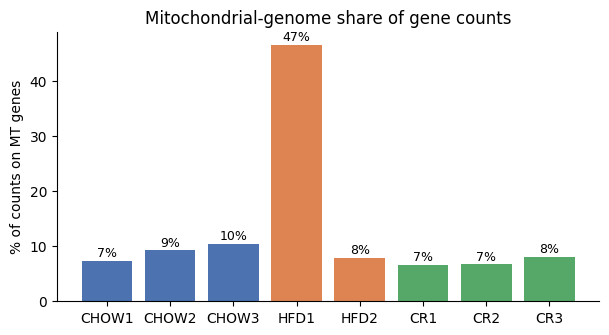

,MT fraction,diet,Label
GSM1163164,7.4%,chow,CHOW1
GSM1163165,9.2%,chow,CHOW2
GSM1163166,10.5%,chow,CHOW3
GSM1163167,46.7%,high fat,HFD1
GSM1163168,7.9%,high fat,HFD2
GSM1163169,6.7%,calorie restricted,CR1
GSM1163170,6.7%,calorie restricted,CR2
GSM1163171,8.1%,calorie restricted,CR3


In [5]:
mt_genes = set(genes.index[genes["seqname"] == "MT"])
mt_frac = counts.loc[:, counts.columns.isin(mt_genes)].sum(axis=1) / counts.sum(axis=1)
mt_tbl = mt_frac.rename("MT fraction").to_frame().join(metadata[["diet", "Label"]])

fig, ax = plt.subplots(figsize=(7, 3.5))
colors = mt_tbl["Label"].str.extract(r"^([A-Z]+)", expand=False).map({"CHOW": "#4C72B0", "HFD": "#DD8452", "CR": "#55A868"})
ax.bar(mt_tbl["Label"], mt_tbl["MT fraction"] * 100, color=colors)
ax.set_ylabel("% of counts on MT genes")
ax.set_title("Mitochondrial-genome share of gene counts")
for i, v in enumerate(mt_tbl["MT fraction"] * 100):
    ax.text(i, v + 0.8, f"{v:.0f}%", ha="center", fontsize=9)
sns.despine()
save(fig, "mt_fraction.png")
plt.show()
mt_tbl.style.format({"MT fraction": "{:.1%}"})

In [6]:
counts = counts.loc[:, ~counts.columns.isin(mt_genes)]
print(f"Removed {len(mt_genes)} MT genes; {counts.shape[1]} genes remain")

Removed 37 MT genes; 78280 genes remain


### PCA and sample correlation

The original paper did not show a sample PCA or correlation matrix. Blind VST counts, top 500 most variable genes,
after MT removal.

/nas/longleaf/home/jaileru/.conda/envs/home/lib/python3.14/site-packages/pydeseq2/dds.py:432: UserWarning: The dispersion trend curve fitting did not converge. Switching to a mean-based dispersion trend.
  self._fit_parametric_dispersion_trend(vst=True)


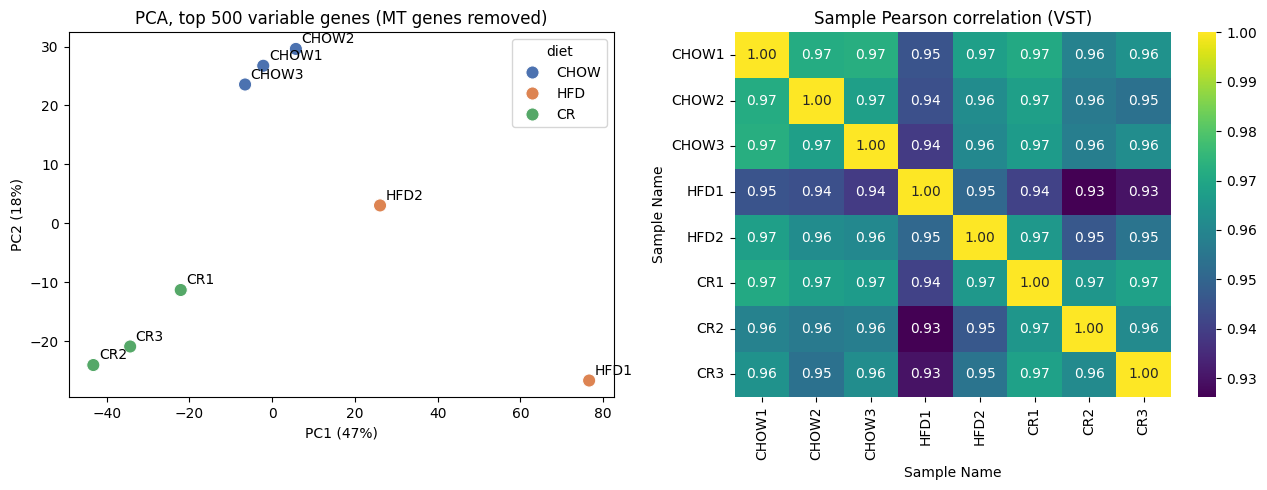

In [7]:
dds = DeseqDataSet(counts=counts, metadata=metadata, design="~diet", inference=inference, quiet=True)
dds.vst(use_design=False)
vst_df = pd.DataFrame(dds.layers["vst_counts"], index=dds.obs_names, columns=dds.var_names)
vst_df.index = vst_df.index.map(metadata["Label"])

top = vst_df.var(axis=0).sort_values(ascending=False).index[:500]
x = vst_df[top] - vst_df[top].mean(axis=0)
u, s, vt = np.linalg.svd(x.values, full_matrices=False)
var_expl = s**2 / (s**2).sum()
pcs = pd.DataFrame(u[:, :2] * s[:2], index=x.index, columns=["PC1", "PC2"])
pcs["diet"] = pcs.index.str.extract(r"^([A-Z]+)", expand=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=pcs, x="PC1", y="PC2", hue="diet", s=90, ax=axes[0],
                palette={"CHOW": "#4C72B0", "HFD": "#DD8452", "CR": "#55A868"})
for lab, r in pcs.iterrows():
    axes[0].annotate(lab, (r.PC1, r.PC2), xytext=(4, 4), textcoords="offset points")
axes[0].set_xlabel(f"PC1 ({var_expl[0]:.0%})")
axes[0].set_ylabel(f"PC2 ({var_expl[1]:.0%})")
axes[0].set_title("PCA, top 500 variable genes (MT genes removed)")
sns.heatmap(vst_df.T.corr(), annot=True, fmt=".2f", cmap="viridis", ax=axes[1])
axes[1].set_title("Sample Pearson correlation (VST)")
plt.tight_layout()
save(fig, "pca_correlation.png")
plt.show()

### What drives the HFD1 outlier

HFD1 sits on the same PC1 axis as the diet effect (CR negative, chow near 0, HFD positive) but about three times
further out than HFD2. Removing MT genes barely moves it (PC1 77.0 to 76.6), and neither does restricting to
well-expressed or protein-coding genes. Comparing each HFD sample with the mean of the other samples over the
top-variable genes separates two groups:

- **Shared HFD signal** (upper right): genes up in both HFD livers but more in HFD1, e.g. *Cidea*, *Gpnmb*,
  *Mmp12*, *Clec4e*, *Sprr1a*: steatosis and lipid-associated macrophage markers.
- **HFD1-only dropouts** (lower centre): genes near zero in HFD1 but normal in HFD2, e.g. *Angptl6*, *Sts*,
  *Metrn*, *Ubxn6*, several ribosomal pseudogenes. This pattern fits a degraded library.

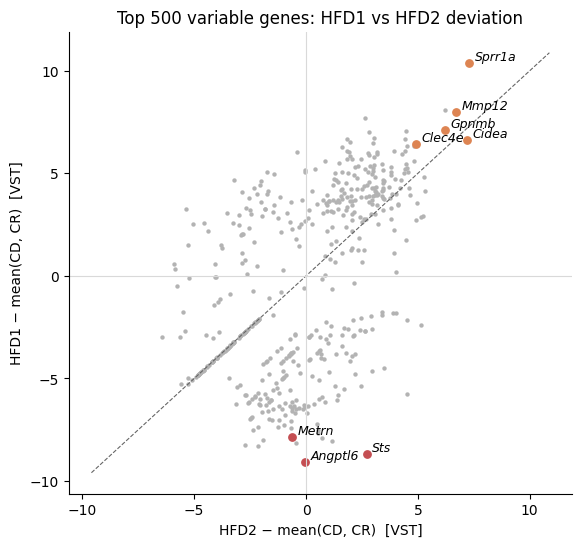

In [8]:
others = vst_df.drop(["HFD1", "HFD2"])
dev = pd.DataFrame({
    "HFD1": vst_df.loc["HFD1", top] - others[top].mean(),
    "HFD2": vst_df.loc["HFD2", top] - others[top].mean(),
}).join(genes["gene_name"])

shared = ["Cidea", "Gpnmb", "Mmp12", "Clec4e", "Sprr1a"]
dropout = ["Angptl6", "Sts", "Metrn"]
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(dev["HFD2"], dev["HFD1"], s=10, color="0.7", lw=0)
for names, col in [(shared, "#DD8452"), (dropout, "#C44E52")]:
    sub = dev[dev["gene_name"].isin(names)]
    ax.scatter(sub["HFD2"], sub["HFD1"], s=28, color=col)
    for _, r in sub.iterrows():
        ax.annotate(r.gene_name, (r.HFD2, r.HFD1), xytext=(4, 2), textcoords="offset points",
                    fontsize=9, style="italic")
lim = [min(dev[["HFD1", "HFD2"]].min()) - 0.5, max(dev[["HFD1", "HFD2"]].max()) + 0.5]
ax.plot(lim, lim, ls="--", color="0.4", lw=0.8)
ax.axhline(0, color="0.85", lw=0.8); ax.axvline(0, color="0.85", lw=0.8)
ax.set_xlabel("HFD2 − mean(CD, CR)  [VST]")
ax.set_ylabel("HFD1 − mean(CD, CR)  [VST]")
ax.set_title("Top 500 variable genes: HFD1 vs HFD2 deviation")
sns.despine()
save(fig, "hfd1_drivers.png")
plt.show()

**Conclusion for HFD1.** It is part a stronger HFD responder and part a damaged library. It is kept in the main
analysis (dropping it leaves n=1 HFD), and every HFD result is checked against a fit without it.

## 2. Differential expression

Paper: CD vs CR = 2029 + 695 overlap (2724 total); CD vs HFD = 2135 + 695 overlap (2830 total).
Like the paper, CD vs CR and CD vs HFD are fit as separate two-group DESeq2 models, then the DEG lists are
intersected. In one 3-group model the HFD1 outlier inflates the shared dispersion estimates and suppresses CD vs CR
DEGs. Thresholds follow the paper: padj < 0.05, |log2FC| ≥ 0.5 (the paper's FPKM ≥ 0.1 filter is not applied).
Pre-filter per comparison: ≥ 10 reads in at least as many samples as the smallest group.

calorie restricted vs chow: 13541 genes after pre-filter (min group size 3)
high fat vs chow: 14133 genes after pre-filter (min group size 2)


/nas/longleaf/home/jaileru/.conda/envs/home/lib/python3.14/site-packages/pydeseq2/dds.py:548: UserWarning: As the residual degrees of freedom is less than 3, the distribution of log dispersions is especially asymmetric and likely to be poorly estimated by the MAD.
  self.fit_dispersion_prior()


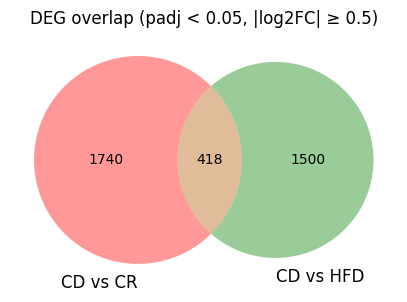

,this analysis,paper
CD vs CR,2158,2724
CD vs HFD,1918,2830
shared,418,695


In [9]:
def pairwise_deseq(level, ref="chow", min_count=10):
    samples = metadata.index[metadata["diet"].isin([ref, level])]
    c = counts.loc[samples]
    min_n = metadata.loc[samples, "diet"].value_counts().min()
    c = c.loc[:, (c >= min_count).sum(axis=0) >= min_n]
    print(f"{level} vs {ref}: {c.shape[1]} genes after pre-filter (min group size {min_n})")
    d = DeseqDataSet(counts=c, metadata=metadata.loc[samples], design="~diet",
                     refit_cooks=True, inference=inference, quiet=True)
    d.deseq2()
    st = DeseqStats(d, contrast=["diet", level, ref], inference=inference, quiet=True)
    st.summary()
    return st.results_df

pw_cr = pairwise_deseq("calorie restricted")
pw_hfd = pairwise_deseq("high fat")

cr_set = deg_set(pw_cr, "padj", 0.05, 0.5)
hfd_set = deg_set(pw_hfd, "padj", 0.05, 0.5)
deg_tbl = pd.DataFrame({
    "this analysis": [len(cr_set), len(hfd_set), len(cr_set & hfd_set)],
    "paper": [2724, 2830, 695],
}, index=["CD vs CR", "CD vs HFD", "shared"])

fig, ax = plt.subplots(figsize=(5, 4))
venn2([cr_set, hfd_set], set_labels=("CD vs CR", "CD vs HFD"), ax=ax)
ax.set_title("DEG overlap (padj < 0.05, |log2FC| ≥ 0.5)")
save(fig, "deg_venn.png")
plt.show()
deg_tbl

### Sensitivity: refit without HFD1

Leaves n=1 HFD, so the HFD numbers are exploratory only.

In [10]:
outlier = metadata.index[metadata["Label"] == "HFD1"]
keep_samples = counts.index.difference(outlier)
dds_no = DeseqDataSet(counts=counts.loc[keep_samples], metadata=metadata.loc[keep_samples], design="~diet",
                      refit_cooks=True, inference=inference, quiet=True)
dds_no.deseq2()

res_no = {}
for name, lvl in [("CD vs CR", "calorie restricted"), ("CD vs HFD", "high fat")]:
    st = DeseqStats(dds_no, contrast=["diet", lvl, "chow"], inference=inference, quiet=True)
    st.summary()
    res_no[name] = st.results_df

pd.DataFrame({
    name: {
        "padj<0.05": len(deg_set(r, "padj", 0.05, 0)),
        "padj<0.05 & |LFC|>=0.5": len(deg_set(r, "padj", 0.05, 0.5)),
    }
    for name, r in res_no.items()
})

,CD vs CR,CD vs HFD
padj<0.05,2010,1672
padj<0.05 & |LFC|>=0.5,2010,1672


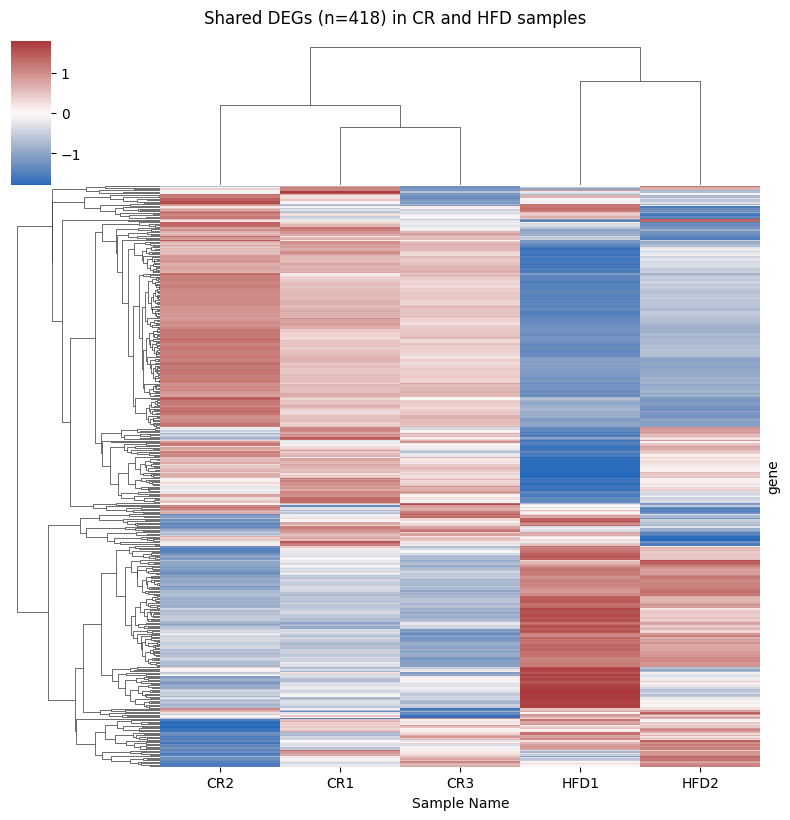

In [11]:
# Shared DEGs (CD vs CR ∩ CD vs HFD), z-scored blind VST values in CR and HFD samples
overlap = cr_set & hfd_set
df = vst_df.loc[~vst_df.index.str.startswith("CHOW"), sorted(overlap)]
df_z = (df - df.mean(axis=0)) / df.std(axis=0)
g = sns.clustermap(df_z.T, method="average", metric="euclidean", cmap="vlag", center=0,
                   figsize=(8, 8), xticklabels=True, yticklabels=False)
g.fig.suptitle(f"Shared DEGs (n={len(overlap)}) in CR and HFD samples", y=1.02)
save(g.fig, "shared_degs_heatmap.png")
plt.show()

## 3. Pathway enrichment: prerank GSEA

GSEA uses the full ranked gene list instead of a DEG cutoff, and keeps the direction of change: a positive NES
means the pathway is shifted up in the diet relative to chow. Ranking statistic: DESeq2 Wald `stat`,
protein-coding genes only, one entry per symbol (largest |stat|). Gene sets: GO Biological Process 2023 (Enrichr,
mouse), 15–500 genes, 1000 permutations.

In [12]:
go_library = gp.get_library(name="GO_Biological_Process_2023", organism="mouse")
go_library = {t: [g.upper() for g in gs] for t, gs in go_library.items()}


def run_gsea(res, seed=0):
    r = res.join(gene_annotations["gene_name"], how="inner").dropna(subset=["stat"])
    r["symbol"] = r["gene_name"].str.upper()
    r = r.reindex(r["stat"].abs().sort_values(ascending=False).index).drop_duplicates("symbol")
    rnk = r.set_index("symbol")["stat"].sort_values(ascending=False)
    pre = gp.prerank(rnk=rnk, gene_sets=go_library, min_size=15, max_size=500,
                     permutation_num=1000, seed=seed, threads=4, outdir=None, no_plot=True)
    out = pre.res2d.copy()
    for c in ["NES", "FDR q-val", "NOM p-val"]:
        out[c] = out[c].astype(float)
    out["Term"] = out["Term"].str.replace(r"\s*\(GO:\d+\)$", "", regex=True)
    return out.set_index("Term")


gsea = {
    "CR vs CD": run_gsea(pw_cr),
    "HFD vs CD": run_gsea(pw_hfd),
    "HFD vs CD\n(no HFD1)": run_gsea(res_no["CD vs HFD"]),
}
for k, v in gsea.items():
    print(f"{k.replace(chr(10), ' ')}: {(v['FDR q-val'] < 0.05).sum()} terms FDR < 0.05 "
          f"({((v['FDR q-val'] < 0.05) & (v['NES'] > 0)).sum()} up, "
          f"{((v['FDR q-val'] < 0.05) & (v['NES'] < 0)).sum()} down)")

2026-11-11 10:00:54,184 [WARNING] Duplicated values found in preranked stats: 0.01% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-11-11 10:01:21,649 [WARNING] Duplicated values found in preranked stats: 8.43% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


CR vs CD: 251 terms FDR < 0.05 (62 up, 189 down)
HFD vs CD: 422 terms FDR < 0.05 (343 up, 79 down)
HFD vs CD (no HFD1): 634 terms FDR < 0.05 (521 up, 113 down)


The dot plot groups selected GO terms by theme. Rows were chosen from the terms significant (FDR < 0.05) in at
least one main contrast, collapsing near-duplicate terms. Colour is NES (red = shifted up vs chow, blue = down),
size is −log10 FDR, and hollow dots are FDR ≥ 0.05. The third column repeats HFD vs chow without HFD1.

The bottom panel holds the strongest terms by FDR overall (ribosome / translation and oxidative phosphorylation).
They are shown separately because they may be partly technical: the ribosomal-protein share of reads varies
about tenfold between samples, and HFD1 has a degraded library.

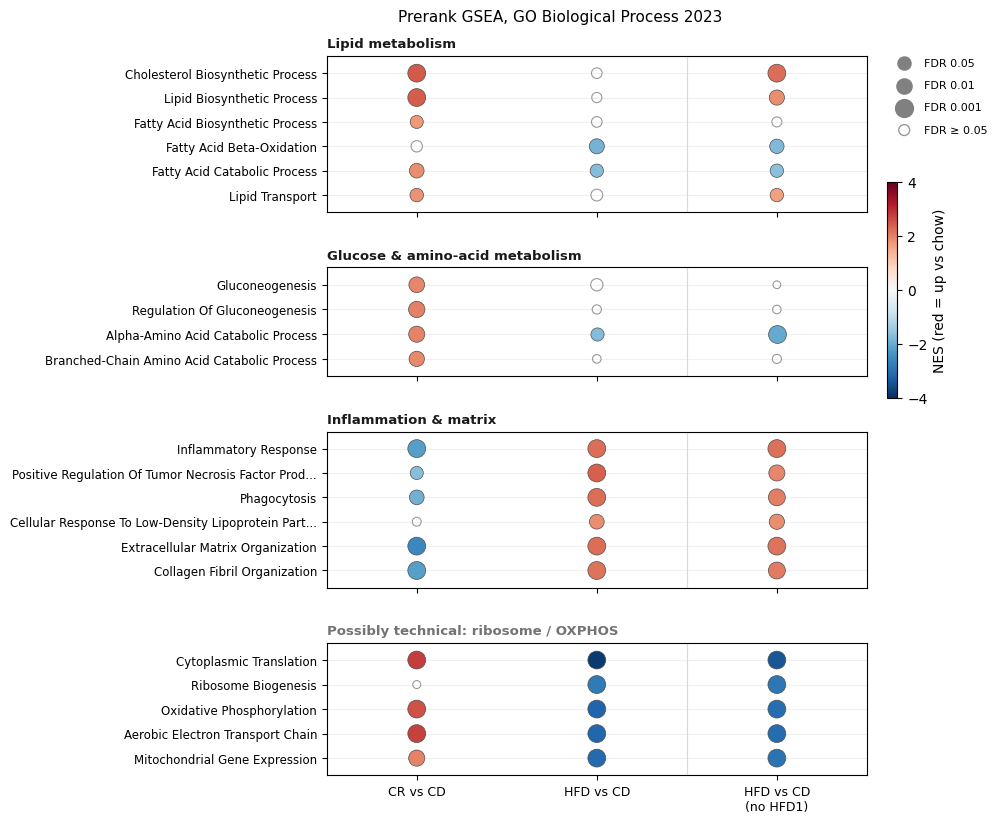

In [13]:
PANELS = {
    "Lipid metabolism": [
        "Cholesterol Biosynthetic Process", "Lipid Biosynthetic Process", "Fatty Acid Biosynthetic Process",
        "Fatty Acid Beta-Oxidation", "Fatty Acid Catabolic Process", "Lipid Transport",
    ],
    "Glucose & amino-acid metabolism": [
        "Gluconeogenesis", "Regulation Of Gluconeogenesis", "Alpha-Amino Acid Catabolic Process",
        "Branched-Chain Amino Acid Catabolic Process",
    ],
    "Inflammation & matrix": [
        "Inflammatory Response", "Positive Regulation Of Tumor Necrosis Factor Production", "Phagocytosis",
        "Cellular Response To Low-Density Lipoprotein Particle Stimulus", "Extracellular Matrix Organization",
        "Collagen Fibril Organization",
    ],
    "Possibly technical: ribosome / OXPHOS": [
        "Cytoplasmic Translation", "Ribosome Biogenesis", "Oxidative Phosphorylation",
        "Aerobic Electron Transport Chain", "Mitochondrial Gene Expression",
    ],
}
cols = list(gsea)
nes = pd.DataFrame({k: v["NES"] for k, v in gsea.items()})
fdr = pd.DataFrame({k: v["FDR q-val"] for k, v in gsea.items()})
missing = [t for ts in PANELS.values() for t in ts if t not in nes.index]
assert not missing, missing
vmax = np.ceil(np.nanmax(np.abs(nes.loc[[t for ts in PANELS.values() for t in ts]].values)))


def size_of(q):
    return 30 + 45 * -np.log10(np.clip(q, 1e-3, 1))


fig, axes = plt.subplots(len(PANELS), 1, figsize=(8.5, 0.34 * sum(map(len, PANELS.values())) + 2.2),
                         gridspec_kw={"height_ratios": [len(v) + 0.6 for v in PANELS.values()], "hspace": 0.4},
                         sharex=True)
for ax, (panel, terms) in zip(axes, PANELS.items()):
    n, q = nes.loc[terms, cols], fdr.loc[terms, cols].fillna(1)
    for j, col in enumerate(cols):
        y = np.arange(len(terms))[::-1]
        sig = (q[col] < 0.05).values
        sc = ax.scatter(np.full(sig.sum(), j), y[sig], s=size_of(q[col].values[sig]), c=n[col].values[sig],
                        cmap="RdBu_r", vmin=-vmax, vmax=vmax, edgecolor="0.3", lw=0.5, zorder=3)
        ax.scatter(np.full((~sig).sum(), j), y[~sig], s=size_of(q[col].values[~sig]), facecolor="none",
                   edgecolor="0.6", lw=0.8, zorder=3)
    ax.set_yticks(np.arange(len(terms))[::-1])
    ax.set_yticklabels([t if len(t) <= 52 else t[:49] + "..." for t in terms], fontsize=8.5)
    ax.set_ylim(-0.7, len(terms) - 0.3)
    ax.set_title(panel, loc="left", fontsize=9.5, fontweight="bold",
                 color="0.45" if panel.startswith("Possibly") else "0.1")
    ax.axvline(1.5, color="0.85", lw=0.8)
    ax.grid(axis="y", color="0.94"); ax.set_axisbelow(True)
axes[-1].set_xticks(range(len(cols))); axes[-1].set_xticklabels(cols, fontsize=9)
axes[-1].set_xlim(-0.5, len(cols) - 0.5)
cb = fig.colorbar(sc, ax=axes, shrink=0.3, pad=0.03, anchor=(0, 0.75)); cb.set_label("NES (red = up vs chow)")
for q in (0.05, 0.01, 0.001):
    axes[0].scatter([], [], s=size_of(q), facecolor="0.5", label=f"FDR {q}")
axes[0].scatter([], [], s=size_of(0.2), facecolor="none", edgecolor="0.6", label="FDR ≥ 0.05")
axes[0].legend(loc="upper left", bbox_to_anchor=(1.03, 1.05), frameon=False, fontsize=8, labelspacing=1.1)
fig.suptitle("Prerank GSEA, GO Biological Process 2023", x=0.4, y=0.93, fontsize=11)
save(fig, "gsea_dotplot.png")
plt.show()

In [14]:
# Agreement of HFD NES with and without HFD1, over all terms tested in both
both = gsea["HFD vs CD"][["NES"]].join(gsea["HFD vs CD\n(no HFD1)"][["NES"]], rsuffix="_noHFD1", how="inner")
print(f"Spearman rho, HFD NES with vs without HFD1: {both.corr(method='spearman').iloc[0, 1]:.2f} "
      f"over {len(both)} terms")

Spearman rho, HFD NES with vs without HFD1: 0.88 over 2091 terms


/tmp/ipykernel_596308/469614198.py:2: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  both = gsea["HFD vs CD"][["NES"]].join(gsea["HFD vs CD\n(no HFD1)"][["NES"]], rsuffix="_noHFD1", how="inner")


In [15]:
# Leading-edge genes behind the plotted terms (first 12 per term)
def leading_edge(k, n=12):
    v = gsea[k].loc[[t for ts in PANELS.values() for t in ts]]
    v = v[v["FDR q-val"] < 0.05].sort_values("NES", ascending=False)
    return pd.DataFrame({
        "NES": v["NES"].round(2),
        "FDR": v["FDR q-val"].map("{:.1e}".format),
        "leading edge": v["Lead_genes"].str.split(";").str[:n].str.join(", "),
    })

pd.set_option("display.max_colwidth", 200)
display(leading_edge("CR vs CD"))
display(leading_edge("HFD vs CD"))

,NES,FDR,leading edge
Term,,,
Cytoplasmic Translation,2.78,0.0e+00,"RPL39, RPL37A, RPL38, RPS7, RPLP1, RPS13, RPS17, RPL10, RPL22L1, RPS19, RPL13, RPS18"
Aerobic Electron Transport Chain,2.72,0.0e+00,"COX5A, NDUFB1, COX7C, SDHC, NDUFB6, NDUFA4, SDHD, NDUFS4, NDUFA9, NDUFC2, COX7B, COX7A2"
Oxidative Phosphorylation,2.55,0.0e+00,"ATP5ME, NDUFB1, ATP5F1E, SDHC, NDUFB6, SDHD, NDUFS4, NDUFA9, NDUFC2, NDUFS3, NDUFA7, NDUFB4"
Cholesterol Biosynthetic Process,2.46,0.0e+00,"HMGCR, INSIG1, NSDHL, MVK, LSS, PMVK, DHCR24, MSMO1, MVD, FDFT1, SC5D, TM7SF2"
Lipid Biosynthetic Process,2.43,0.0e+00,"HMGCR, MVK, ACSS2, LSS, HSD3B2, SREBF1, MVD, FDFT1, ACSM5, FASN, ACLY, ACSM1"
Regulation Of Gluconeogenesis,2.00,3.9e-03,"GCK, CRY1, GNMT, PGPEP1, FOXO1, DGKQ, OGT, PPARGC1A, FBP1, SDHAF3, SIRT7, EP300"
Alpha-Amino Acid Catabolic Process,1.99,4.7e-03,"THNSL2, MCCC1, SARDH, HOGA1, PRODH, ALDH4A1, IVD, ALDH6A1, MTRR, HMGCL, OTC, ACMSD"
Mitochondrial Gene Expression,1.99,4.6e-03,"MRPL23, MRPS34, LARS2, MRPS24, MRPS16, GATB, MRPL28, MRPS21, FOXO3, NDUFA7, MRPL10, FASTKD1"
Gluconeogenesis,1.96,6.8e-03,"PER2, PGK1, PFKFB1, CRY1, SLC37A4, MDH1, SLC25A13, PGAM1, SLC39A14, SLC25A1, ENO3, PPARGC1A"


,NES,FDR,leading edge
Term,,,
Positive Regulation Of Tumor Necrosis Factor Production,2.38,0.0e+00,"OAS3, EPHB2, CCR2, PTPRC, RASGRP1, TLR3, TLR1, CLEC7A, PTPRJ, RIGI, THBS1, TLR4"
Inflammatory Response,2.24,7.5e-04,"CCR2, CXCL9, ITGB2, SIGLEC1, CYBB, VCAM1, HDAC9, C3AR1, CCR5, ITGAL, TLR3, PPBP"
Extracellular Matrix Organization,2.23,8.8e-04,"MMP12, COL3A1, COL1A1, MMP13, COL1A2, LOXL2, NID1, CREB3L1, TGFB2, COL5A2, COL14A1, ADAMTS12"
Phagocytosis,2.22,6.6e-04,"ITGB2, CD36, MSR1, CD93, ELMO1, TLR4, ARHGAP25, MYH9, ITGAV, BIN2, ADORA1, RAB11FIP2"
Collagen Fibril Organization,2.19,7.3e-04,"COL3A1, COL1A1, COL1A2, LOXL2, TGFB2, COL5A2, COL14A1, DDR2, ATP7A, COL5A1, TGFBR1, LOX"
Cellular Response To Low-Density Lipoprotein Particle Stimulus,1.85,1.5e-02,"ITGB2, CD36, CD68, TLR4, LCP1, PPARG, MIA3, FCER1G, TREM2, SYK, TICAM1, LDLR"
Alpha-Amino Acid Catabolic Process,-1.72,4.6e-02,"HSD17B10, HPD, CBS, HIBADH, TAT, MCCC2, HMGCL, PRODH, HOGA1, ACMSD, IVD, THNSL2"
Fatty Acid Catabolic Process,-1.73,4.4e-02,"HSD17B10, ECI2, ACAA2, EHHADH, ECI1, ACOT8, ILVBL, CPT2, PHYH, MCAT, NUDT19, ECHDC2"
Fatty Acid Beta-Oxidation,-1.89,1.1e-02,"ETFB, HSD17B10, ECI2, ACAA2, EHHADH, ECI1, ACOT8, AMACR, CPT2, GCDH, MCAT, ECHDC2"


## Summary

- **Sample QC.** HFD1 (GSM1163167) is the clear outlier. 47% of its counts fall on mitochondrial genes
  (7–10% elsewhere), and many genes drop out. On top of that it shows a stronger HFD signature than HFD2. Removing
  MT genes does not move it on the PCA. The original paper did not show a sample PCA, so this was not visible there.
- **DEGs.** Separate pairwise fits give 2,158 CD vs CR and 1,918 CD vs HFD DEGs (418 shared), against the
  paper's 2,724, 2,830 and 695. The gap is consistent with the method differences (STAR / GRCm39 vs TopHat / mm9,
  DESeq2 size factors vs CQN, no FPKM filter).
- **CR vs chow.** Shifted up: cholesterol, sterol and lipid biosynthesis, gluconeogenesis and amino-acid
  catabolism. Shifted down: inflammatory response, TNF production, phagocytosis and extracellular matrix /
  collagen organization.
- **HFD vs chow.** The reverse on inflammation: inflammatory response, TNF production, phagocytosis, response to
  LDL and ECM / collagen terms are shifted up, consistent with macrophage infiltration and early fibrotic
  remodelling. Fatty-acid β-oxidation, fatty-acid catabolism and α-amino-acid catabolism are shifted down.
- **Effect of HFD1.** HFD NES values with and without HFD1 agree well (Spearman ρ 0.88). Without HFD1, cholesterol
  and lipid biosynthesis also become significantly up in HFD, so the outlier masks that signal.
- **Caution.** The top-ranked terms overall are ribosome / translation and OXPHOS, up in CR and down in HFD.
  They track the sample-to-sample variation in ribosomal-protein reads and HFD1's library quality, so they are
  not interpreted biologically here.